In [ ]:
#

In [ ]:
# configuring the path of kaggle.json file
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
# uploading our Kaggle API key to colabs

from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving kaggle (4).json to kaggle (4).json
User uploaded file "kaggle (4).json" with length 70 bytes


In [ ]:

# Using kaggle APi key to download face mask dataset from the publisher's account
!kaggle datasets download -d omkargurav/face-mask-dataset

Dataset URL: https://www.kaggle.com/datasets/omkargurav/face-mask-dataset
License(s): unknown
 89% 145M/163M [00:00<00:00, 1.51GB/s]
100% 163M/163M [00:00<00:00, 1.47GB/s]


In [ ]:
# extracting the dataset using python script
from zipfile import ZipFile
dataset_path = '/content/face-mask-dataset.zip'

with ZipFile(dataset_path,'r') as zip:
  zip.extractall('/content/data') # Extract to a new directory named 'data'
  print('Done extracting the dataset')

Done extracting the dataset


In [ ]:
# Importing the required dependencies
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2 # This is for image processing
from google.colab.patches import cv2_imshow
from PIL import Image # This is for image processing
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras
from keras.models import Sequential

In [ ]:
# Accessing all the images in the with mask folder
with_mask_files = os.listdir('/content/data/data/with_mask')

In [ ]:
# printing the first five images in the folder
print(with_mask_files[:5])
print()
# print the last five images in the folder
print(with_mask_files[-5:])

['with_mask_3690.jpg', 'with_mask_2831.jpg', 'with_mask_474.jpg', 'with_mask_1981.jpg', 'with_mask_1299.jpg']

['with_mask_2639.jpg', 'with_mask_2258.jpg', 'with_mask_2141.jpg', 'with_mask_2968.jpg', 'with_mask_3479.jpg']


In [ ]:
# Accessing all the images in the without mask folder
without_mask_files = os.listdir('/content/data/data/without_mask')
# printing the first five images in the folder
print(without_mask_files[:5])
print()
# print the last five images in the folder
print(without_mask_files[-5:])

['without_mask_1861.jpg', 'without_mask_492.jpg', 'without_mask_3472.jpg', 'without_mask_527.jpg', 'without_mask_1898.jpg']

['without_mask_2233.jpg', 'without_mask_2435.jpg', 'without_mask_2833.jpg', 'without_mask_3388.jpg', 'without_mask_1289.jpg']


In [ ]:
# Checking for the total number of images in the with mask folder
print('Total number of images with mask is:', len(with_mask_files))

Total number of images with mask is: 3725


In [ ]:
# Checking for the total number of images in the with mask folder
print('Total number of images without mask is:', len(without_mask_files))

Total number of images without mask is: 3828


In [ ]:
# Checking for the difference between the number of mask and without mask images
print('Difference between the number of images with mask and without mask is:', len(without_mask_files) - len(with_mask_files))

Difference between the number of images with mask and without mask is: 103


CREATING LABELS

In [ ]:
 # Creating the labels for with mask files to be ones (1's)
with_mask_labels = [1]*len(with_mask_files)

In [ ]:
with_mask_labels[:10]

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

In [ ]:
without_mask_labels = [0] * len(without_mask_files)

In [ ]:
without_mask_labels[:10]

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

# Viewing the images

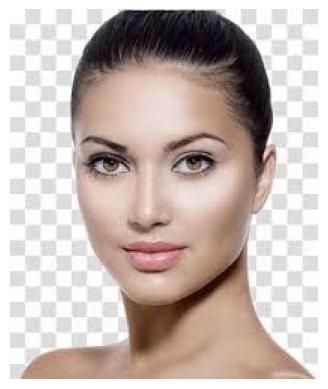

In [ ]:
# Displaying individuals images  with face mask
img =mpimg.imread('/content/data/data/without_mask/without_mask_3537.jpg')
imgplot = plt.imshow(img)
plt.axis('off')
plt.show()

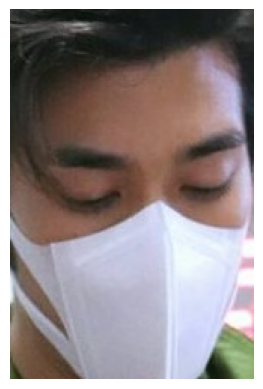

In [ ]:
# Displaying individuals images  with face mask
img =mpimg.imread('/content/data/data/with_mask/with_mask_1099.jpg')
imgplot = plt.imshow(img)
plt.axis('off')
plt.show()

IMAGE PROCESSING STAGE

In [ ]:
# resizing and converting all the images to numpy array
from  warnings import filterwarnings
filterwarnings('ignore')

mask_path = '/content/data/data/with_mask/'
images=[]



for img_file in with_mask_files:
  image=Image.open(mask_path + img_file)
  image=image.resize((128,128))
  image=image.convert('RGB')
  image=np.array(image)
  images.append(image)


  without_mask_path = '/content/data/data/without_mask/'
for img_file in without_mask_files:
  image=Image.open(without_mask_path + img_file)
  image=image.resize((128,128))
  image=image.convert('RGB')
  image=np.array(image)
  images.append(image)

In [ ]:
  # viewing the length of the combined resize images
print(len(images))

7553


In [ ]:
# checking for the size and the color channel in the first resized image
images[0].shape

(128, 128, 3)

In [ ]:
# checking for the size and the color channel in the first resized image
images[-1].shape

(128, 128, 3)

COMBINING THE LABELS INTO A SINGLE VARIABLE

In [ ]:
# combining the two labels to be one
labels= with_mask_labels + without_mask_labels

In [ ]:
labels[:20]
labels[-20:]

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

array([[[ 35,  66,  25],
        [ 87, 120,  69],
        [ 73, 106,  46],
        ...,
        [130, 151,  94],
        [172, 194, 140],
        [113, 137,  88]],

       [[ 59,  89,  50],
        [110, 142,  94],
        [ 68, 101,  40],
        ...,
        [106, 125,  69],
        [156, 175, 125],
        [ 83, 104,  63]],

       [[ 68,  95,  59],
        [ 60,  89,  44],
        [107, 138,  81],
        ...,
        [186, 201, 149],
        [208, 222, 180],
        [143, 159, 125]],

       ...,

       [[179, 180, 175],
        [183, 184, 179],
        [189, 190, 185],
        ...,
        [ 70,  80,  69],
        [ 69,  79,  69],
        [ 63,  75,  65]],

       [[182, 184, 179],
        [179, 181, 176],
        [190, 191, 186],
        ...,
        [ 75,  82,  74],
        [ 70,  79,  71],
        [ 64,  75,  66]],

       [[185, 190, 184],
        [179, 182, 176],
        [184, 186, 181],
        ...,
        [ 82,  87,  81],
        [ 73,  80,  73],
        [ 64,  74,  67]]], dtype=uint8)
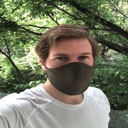

In [ ]:
images[1]

array([[[252, 255, 226],
        [253, 255, 229],
        [254, 255, 231],
        ...,
        [255, 247, 218],
        [254, 249, 219],
        [254, 250, 220]],

       [[252, 255, 228],
        [253, 255, 230],
        [254, 255, 232],
        ...,
        [251, 242, 213],
        [252, 242, 213],
        [252, 241, 213]],

       [[253, 255, 232],
        [253, 255, 232],
        [253, 255, 233],
        ...,
        [251, 242, 213],
        [252, 239, 212],
        [252, 237, 210]],

       ...,

       [[ 79,  67,  69],
        [ 85,  74,  76],
        [ 87,  77,  78],
        ...,
        [ 87,  73,  74],
        [ 89,  75,  75],
        [ 83,  69,  69]],

       [[ 64,  52,  54],
        [ 71,  60,  61],
        [ 80,  70,  71],
        ...,
        [ 81,  67,  67],
        [ 78,  64,  64],
        [ 75,  61,  61]],

       [[ 49,  37,  39],
        [ 63,  52,  54],
        [ 79,  69,  70],
        ...,
        [ 69,  55,  55],
        [ 71,  57,  57],
        [ 65,  51,  51]]], dtype=uint8)
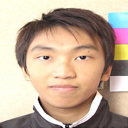

In [ ]:
images[-1]

In [ ]:
# conveting the labels and the combined images we created before to a numpy array
x=np.array(images)
y=np.array(labels)

array([[[124, 120, 147],
        [120, 116, 142],
        [113, 109, 136],
        ...,
        [ 72,  75,  53],
        [ 54,  57,  36],
        [ 52,  55,  34]],

       [[142, 139, 155],
        [132, 129, 151],
        [125, 121, 150],
        ...,
        [ 67,  69,  49],
        [ 57,  60,  39],
        [ 61,  64,  43]],

       [[158, 156, 167],
        [151, 148, 164],
        [140, 136, 158],
        ...,
        [ 70,  74,  46],
        [ 72,  77,  49],
        [ 71,  75,  51]],

       ...,

       [[  1,   1,   1],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  1,   1,   1],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[  1,   1,   1],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]]], dtype=uint8)
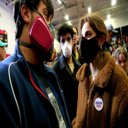

In [ ]:
x[5]

**DATA SPLITING**

In [ ]:
# let's split the combine image data into training and test sets

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=2)
# printing the shape of the x-array and the x_train and x_test values


print("The training size is:", x_train.shape)
print("the test size is:",x_test.shape)

The training size is: (6042, 128, 128, 3)
the test size is: (1511, 128, 128, 3)


array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)
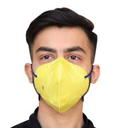

In [ ]:
# visulizing the first three images in the training data
x_train[0]

array([[[92, 80, 82],
        [96, 85, 86],
        [94, 84, 85],
        ...,
        [70, 65, 69],
        [69, 65, 67],
        [70, 66, 67]],

       [[95, 85, 86],
        [80, 70, 71],
        [60, 51, 52],
        ...,
        [65, 60, 64],
        [68, 64, 66],
        [68, 64, 65]],

       [[72, 69, 67],
        [60, 56, 55],
        [42, 39, 38],
        ...,
        [54, 50, 51],
        [57, 53, 54],
        [59, 55, 56]],

       ...,

       [[37, 37, 37],
        [29, 29, 29],
        [23, 23, 23],
        ...,
        [82, 61, 50],
        [70, 51, 40],
        [63, 45, 35]],

       [[36, 36, 36],
        [30, 30, 30],
        [23, 23, 23],
        ...,
        [86, 63, 52],
        [82, 62, 51],
        [82, 64, 54]],

       [[33, 33, 33],
        [32, 32, 32],
        [29, 29, 29],
        ...,
        [73, 50, 39],
        [71, 51, 41],
        [78, 58, 49]]], dtype=uint8)
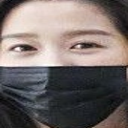

In [ ]:
x_train[6000]

array([[[156, 188, 203],
        [156, 188, 203],
        [156, 188, 203],
        ...,
        [168, 195, 214],
        [168, 195, 214],
        [168, 195, 214]],

       [[156, 188, 203],
        [156, 188, 203],
        [156, 188, 203],
        ...,
        [168, 195, 214],
        [168, 195, 214],
        [168, 195, 214]],

       [[156, 188, 203],
        [156, 188, 203],
        [156, 188, 203],
        ...,
        [168, 195, 214],
        [168, 195, 214],
        [168, 195, 214]],

       ...,

       [[247, 192, 143],
        [248, 196, 151],
        [250, 202, 160],
        ...,
        [123, 165, 177],
        [123, 165, 177],
        [123, 165, 177]],

       [[251, 196, 147],
        [251, 199, 154],
        [252, 204, 162],
        ...,
        [122, 164, 176],
        [122, 164, 176],
        [122, 164, 176]],

       [[253, 199, 149],
        [252, 201, 155],
        [252, 204, 162],
        ...,
        [122, 164, 176],
        [122, 164, 176],
        [122, 164, 176]]], dtype=uint8)
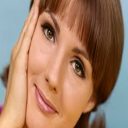

In [ ]:
x_train[20]

array([[[ 66,  66,  66],
        [ 61,  61,  61],
        [ 56,  56,  56],
        ...,
        [194, 194, 174],
        [188, 189, 173],
        [184, 186, 172]],

       [[ 67,  67,  67],
        [ 62,  62,  62],
        [ 57,  57,  57],
        ...,
        [195, 195, 175],
        [191, 192, 176],
        [190, 192, 179]],

       [[ 62,  65,  63],
        [ 57,  58,  58],
        [ 51,  52,  54],
        ...,
        [194, 194, 175],
        [190, 191, 174],
        [189, 191, 178]],

       ...,

       [[ 42,  34,  31],
        [ 44,  36,  32],
        [ 49,  40,  35],
        ...,
        [ 27,  25,  26],
        [ 31,  29,  30],
        [ 33,  31,  32]],

       [[ 44,  36,  33],
        [ 41,  33,  29],
        [ 44,  35,  30],
        ...,
        [ 26,  24,  25],
        [ 28,  26,  27],
        [ 31,  29,  30]],

       [[ 44,  36,  33],
        [ 39,  31,  27],
        [ 40,  31,  26],
        ...,
        [ 25,  23,  24],
        [ 27,  25,  26],
        [ 28,  26,  27]]], dtype=uint8)
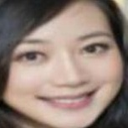

In [ ]:
x_train[30]

array([[[199, 200, 195],
        [199, 200, 195],
        [199, 200, 195],
        ...,
        [210, 211, 206],
        [210, 211, 206],
        [210, 211, 206]],

       [[199, 200, 195],
        [199, 200, 195],
        [199, 200, 195],
        ...,
        [210, 211, 206],
        [210, 211, 206],
        [210, 211, 206]],

       [[199, 200, 195],
        [199, 200, 195],
        [199, 200, 195],
        ...,
        [210, 211, 206],
        [210, 211, 206],
        [210, 211, 206]],

       ...,

       [[195, 207, 196],
        [202, 213, 200],
        [209, 212, 200],
        ...,
        [226, 174, 134],
        [223, 171, 131],
        [223, 171, 131]],

       [[199, 211, 199],
        [202, 212, 199],
        [208, 211, 199],
        ...,
        [228, 176, 136],
        [225, 173, 133],
        [225, 173, 133]],

       [[202, 214, 202],
        [204, 214, 201],
        [210, 213, 201],
        ...,
        [229, 177, 137],
        [226, 174, 134],
        [226, 174, 134]]], dtype=uint8)
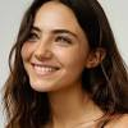

In [ ]:
x_train[40]

array([[[240, 242, 241],
        [240, 242, 241],
        [240, 242, 241],
        ...,
        [244, 244, 246],
        [244, 244, 246],
        [245, 245, 247]],

       [[240, 242, 241],
        [240, 242, 241],
        [240, 242, 241],
        ...,
        [244, 244, 246],
        [244, 244, 246],
        [245, 245, 247]],

       [[240, 242, 241],
        [240, 242, 241],
        [240, 242, 241],
        ...,
        [244, 244, 246],
        [244, 244, 246],
        [245, 245, 247]],

       ...,

       [[100,  83,  57],
        [ 99,  82,  56],
        [ 97,  80,  54],
        ...,
        [ 96,  78,  54],
        [ 97,  79,  55],
        [ 97,  79,  55]],

       [[ 98,  81,  55],
        [ 97,  80,  54],
        [ 96,  79,  53],
        ...,
        [ 96,  78,  54],
        [ 97,  79,  55],
        [ 96,  79,  54]],

       [[100,  83,  56],
        [ 98,  81,  53],
        [ 95,  78,  51],
        ...,
        [ 94,  77,  53],
        [ 96,  80,  55],
        [ 98,  81,  56]]], dtype=uint8)
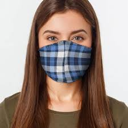

In [ ]:
x_train[600]

array([[[115, 129, 138],
        [103, 118, 127],
        [ 77,  90,  99],
        ...,
        [ 25,  20,  17],
        [ 25,  20,  17],
        [ 25,  20,  17]],

       [[ 89, 102, 111],
        [ 81,  93, 102],
        [ 60,  72,  80],
        ...,
        [ 26,  20,  17],
        [ 25,  20,  17],
        [ 25,  20,  17]],

       [[ 58,  67,  76],
        [ 54,  63,  72],
        [ 42,  52,  59],
        ...,
        [ 26,  21,  18],
        [ 25,  21,  18],
        [ 25,  21,  18]],

       ...,

       [[110, 164, 181],
        [109, 163, 179],
        [108, 160, 176],
        ...,
        [169, 113,  68],
        [167, 111,  67],
        [165, 111,  67]],

       [[111, 165, 180],
        [110, 163, 178],
        [108, 160, 174],
        ...,
        [165, 110,  66],
        [164, 110,  66],
        [162, 110,  66]],

       [[111, 165, 179],
        [110, 163, 177],
        [108, 160, 174],
        ...,
        [163, 108,  63],
        [163, 110,  66],
        [163, 110,  66]]], dtype=uint8)
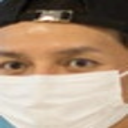

In [ ]:
# let's visualize the images in the test data
x_test[0]

array([[[31, 31, 32],
        [28, 29, 29],
        [19, 19, 18],
        ...,
        [35, 41, 38],
        [35, 41, 39],
        [35, 41, 39]],

       [[29, 29, 29],
        [27, 27, 27],
        [19, 19, 18],
        ...,
        [34, 41, 37],
        [34, 40, 38],
        [34, 40, 38]],

       [[25, 24, 24],
        [24, 24, 22],
        [20, 19, 17],
        ...,
        [33, 40, 36],
        [33, 39, 37],
        [33, 39, 37]],

       ...,

       [[27, 26, 32],
        [27, 26, 31],
        [28, 27, 31],
        ...,
        [59, 52, 29],
        [50, 43, 21],
        [45, 40, 18]],

       [[25, 24, 30],
        [26, 25, 30],
        [29, 28, 33],
        ...,
        [54, 47, 23],
        [44, 38, 16],
        [40, 35, 13]],

       [[25, 24, 29],
        [26, 25, 30],
        [29, 29, 33],
        ...,
        [51, 44, 21],
        [41, 35, 13],
        [37, 32, 10]]], dtype=uint8)
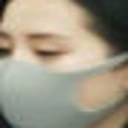

In [ ]:
x_test[400]

array([[[ 52,  42,  33],
        [ 26,  15,   6],
        [ 34,  20,  10],
        ...,
        [132, 104, 105],
        [134, 101, 100],
        [136,  98,  95]],

       [[ 52,  42,  33],
        [ 26,  15,   6],
        [ 33,  20,  10],
        ...,
        [127, 101, 102],
        [130,  99,  98],
        [132,  96,  94]],

       [[ 50,  40,  31],
        [ 24,  13,   4],
        [ 31,  18,   9],
        ...,
        [119,  95,  98],
        [123,  95,  95],
        [124,  93,  91]],

       ...,

       [[240, 204, 167],
        [250, 208, 169],
        [250, 200, 155],
        ...,
        [ 45,  44,  52],
        [ 56,  55,  63],
        [ 46,  45,  53]],

       [[238, 202, 165],
        [248, 206, 167],
        [248, 198, 154],
        ...,
        [ 49,  48,  56],
        [ 52,  51,  59],
        [ 45,  44,  52]],

       [[238, 202, 165],
        [248, 206, 167],
        [249, 198, 154],
        ...,
        [ 54,  53,  61],
        [ 52,  51,  59],
        [ 42,  41,  49]]], dtype=uint8)
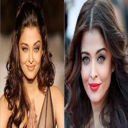

In [ ]:
x_test[10]

array([[[  0,   6,   7],
        [  7,   9,   6],
        [  9,   3,   0],
        ...,
        [  8,   2,   5],
        [  6,   4,   7],
        [  2,   3,   1]],

       [[  3,   5,   3],
        [ 40,  36,  27],
        [ 51,  39,  23],
        ...,
        [ 71,  62,  63],
        [ 15,  11,  12],
        [  0,   1,   0]],

       [[ 19,  12,   5],
        [ 68,  52,  38],
        [ 75,  51,  27],
        ...,
        [ 97,  84,  83],
        [ 18,  11,  10],
        [  0,   1,   0]],

       ...,

       [[ 22,   8,   4],
        [108,  85,  54],
        [139, 100,  51],
        ...,
        [ 57,  43,  34],
        [ 14,   6,   2],
        [  0,   1,   0]],

       [[ 11,   3,   1],
        [ 97,  78,  52],
        [131,  99,  54],
        ...,
        [ 58,  45,  36],
        [ 13,   7,   2],
        [  0,   1,   0]],

       [[  5,   2,   1],
        [ 67,  53,  29],
        [ 87,  58,  19],
        ...,
        [ 48,  36,  27],
        [ 13,   6,   2],
        [  0,   1,   1]]], dtype=uint8)
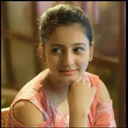

In [ ]:
x_test[20]

array([[[ 28,  17,  21],
        [ 26,  15,  19],
        [ 26,  16,  19],
        ...,
        [132, 129, 136],
        [129, 126, 133],
        [132, 129, 136]],

       [[ 25,  14,  18],
        [ 20,   9,  13],
        [ 18,   7,   9],
        ...,
        [143, 140, 147],
        [136, 133, 141],
        [133, 130, 138]],

       [[ 22,  11,  15],
        [ 18,   7,  11],
        [ 15,   6,   7],
        ...,
        [154, 151, 160],
        [145, 142, 151],
        [137, 134, 143]],

       ...,

       [[ 39,  30,  31],
        [ 49,  40,  41],
        [ 48,  39,  40],
        ...,
        [  9,   7,   8],
        [ 10,   7,   7],
        [ 11,   7,   6]],

       [[ 36,  26,  27],
        [ 55,  45,  46],
        [ 61,  51,  52],
        ...,
        [ 10,   8,   7],
        [ 11,   8,   7],
        [ 12,   8,   7]],

       [[ 36,  26,  27],
        [ 59,  49,  50],
        [ 67,  57,  58],
        ...,
        [ 10,   9,   7],
        [ 11,   9,   7],
        [ 12,   8,   7]]], dtype=uint8)
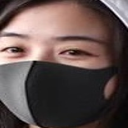

In [ ]:
x_test[30]

In [ ]:
y_train[0]

np.int64(1)

In [ ]:
y_train[20]

np.int64(0)

In [ ]:
y_train[30]

np.int64(0)

In [ ]:
y_train[40]

np.int64(0)

**DATA SCALING**

In [ ]:
# Data scaling
x_train_scaled = x_train/255
x_test_scaled = x_test/255

In [ ]:
# checking the first scaled value for the x_train
print(x_train_scaled)

[[[[1.         1.         1.        ]
   [1.         1.         1.        ]
   [1.         1.         1.        ]
   ...
   [1.         1.         1.        ]
   [1.         1.         1.        ]
   [1.         1.         1.        ]]

  [[1.         1.         1.        ]
   [1.         1.         1.        ]
   [1.         1.         1.        ]
   ...
   [1.         1.         1.        ]
   [1.         1.         1.        ]
   [1.         1.         1.        ]]

  [[1.         1.         1.        ]
   [1.         1.         1.        ]
   [1.         1.         1.        ]
   ...
   [1.         1.         1.        ]
   [1.         1.         1.        ]
   [1.         1.         1.        ]]

  ...

  [[1.         1.         1.        ]
   [1.         1.         1.        ]
   [1.         1.         1.        ]
   ...
   [1.         1.         1.        ]
   [1.         1.         1.        ]
   [1.         1.         1.        ]]

  [[1.         1.         1.        ]
   [1. 

In [ ]:
# checking the first scaled value for the x_train
print(x_test_scaled)

[[[[0.45098039 0.50588235 0.54117647]
   [0.40392157 0.4627451  0.49803922]
   [0.30196078 0.35294118 0.38823529]
   ...
   [0.09803922 0.07843137 0.06666667]
   [0.09803922 0.07843137 0.06666667]
   [0.09803922 0.07843137 0.06666667]]

  [[0.34901961 0.4        0.43529412]
   [0.31764706 0.36470588 0.4       ]
   [0.23529412 0.28235294 0.31372549]
   ...
   [0.10196078 0.07843137 0.06666667]
   [0.09803922 0.07843137 0.06666667]
   [0.09803922 0.07843137 0.06666667]]

  [[0.22745098 0.2627451  0.29803922]
   [0.21176471 0.24705882 0.28235294]
   [0.16470588 0.20392157 0.23137255]
   ...
   [0.10196078 0.08235294 0.07058824]
   [0.09803922 0.08235294 0.07058824]
   [0.09803922 0.08235294 0.07058824]]

  ...

  [[0.43137255 0.64313725 0.70980392]
   [0.42745098 0.63921569 0.70196078]
   [0.42352941 0.62745098 0.69019608]
   ...
   [0.6627451  0.44313725 0.26666667]
   [0.65490196 0.43529412 0.2627451 ]
   [0.64705882 0.43529412 0.2627451 ]]

  [[0.43529412 0.64705882 0.70588235]
   [0.4

BUILDING THE ARCHITECTURE OF THE CNN MODEL

In [ ]:
# Storing the number of classes in the images into a variable
num_of_classes =2

model=keras.Sequential()

model.add(keras.layers.Conv2D(32,kernel_size=(3,3),activation='relu',input_shape=(128,128,3)))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Conv2D(64,kernel_size=(3,3),activation='relu'))
model.add(keras.layers.MaxPooling2D(pool_size=(2,2)))

model.add(keras.layers.Flatten())

model.add(keras.layers.Dense(128,activation='relu'))
model.add(keras.layers.Dropout(0.5))

model.add(keras.layers.Dense(64,activation='relu'))
model.add(keras.layers.Dropout(0.5))

model.add(keras.layers.Dense(num_of_classes,activation='sigmoid')) # sigmoid activivation function is used mainly for binary classification problem

In [ ]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

TRAIINING THE CNN MODEL WITH THE IMAGES

In [ ]:
cnn_history = model.fit(x_train_scaled,y_train,validation_split=0.1,epochs=5)

Epoch 1/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.7190 - loss: 0.6912 - val_accuracy: 0.8777 - val_loss: 0.3113
Epoch 2/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8716 - loss: 0.3126 - val_accuracy: 0.9207 - val_loss: 0.1970
Epoch 3/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9038 - loss: 0.2425 - val_accuracy: 0.9273 - val_loss: 0.1697
Epoch 4/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9252 - loss: 0.1926 - val_accuracy: 0.9322 - val_loss: 0.1736
Epoch 5/5
170/170 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9392 - loss: 0.1675 - val_accuracy: 0.9438 - val_loss: 0.1512


In [ ]:
# evaluating the model with the test data
test_loss, test_accuracy = model.evaluate(x_test_scaled,y_test)
print("Test Accuracy is: ", round(test_accuracy, 2))

48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9354 - loss: 0.1838
Test Accuracy is:  0.93


DEVELOPING A PREDICTIVE INTERFACE FOR THE MODEL

Path of the image to be predicted: /content/face-mask.jpg


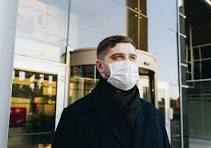

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Prediction: [[0.03608758 0.9299727 ]]
Predicted label: 1
The person in the image is not wearing a mask


In [ ]:
input_image_path = input('Path of the image to be predicted: ')
input_image = cv2.imread(input_image_path)

# Check if image was successfully loaded
if input_image is None:
    print("Error: Could not read the image. Please check the path.")
else:
    cv2_imshow(input_image)

    # Preprocess the image
    input_image_resized = cv2.resize(input_image, (128, 128))
    input_image_scaled = input_image_resized / 255.0
    input_image_reshaped = np.reshape(input_image_scaled, [1, 128, 128, 3])

    # Make a prediction
    input_prediction = model.predict(input_image_reshaped)
    print("Prediction:", input_prediction)

    # Get the predicted label
    input_pred_label = np.argmax(input_prediction)
    print("Predicted label:", input_pred_label)

    # Interpret the prediction
    if input_pred_label == 1:
        print('The person in the image is not wearing a mask')
    else:
        print('The person in the image is wearing a mask')